# The variogram as an inference

Classical geostatistics asks for a variogram before it predicts anything. We compute an experimental
variogram from pairs of data, choose a model, fit its parameters by eye or by least squares, and pass
it to kriging. Each step carries choices, the direction classes, the lag bins, the model, the weights
of the fit, and with a few hundred data the result moves a lot with them. Here we run that route on a
field whose anisotropic variogram we know, and then read the variogram off an ensemble instead, from
the field it estimates and the members it draws.

## What you will learn

- How a variogram fitted to the data by direction can miss the direction and the ranges of the field.
- Why the map of an ensemble gives the direction of the structures while overstating their ranges.
- Why the members of a drawing decoder keep the ranges the map loses.
- How well the ensemble route recovers the anisotropy on several fields, an isotropic one included.

*Can we infer the variogram of a field from an ensemble, instead of fitting it by hand?*

## The idea

An ensemble does not need a variogram. The Pareto search chooses its granularity from the data, while the adaptive IDW fits a direction inside every cell. The structure of the field enters the predictions
without being written down, so we can try to read it back out.

Two products of the ensemble carry it, in different ways.

- **The map**, the mean of the members, keeps the direction in which the field is elongated. As any
  average, it is smoother than the field, so its correlation reaches further than the field's.
- **The members** of a drawing decoder are observed values placed by the partitions. The book behind
  Spatialize treats them as replicates of the field drawn from its predictive law, in its chapter on
  inference for the latent objects. They keep the dispersion of the data at every location, so their
  correlation lengths are those of the field, not of its average.

The route is then to take the direction from the map and the variogram along and across it from the
members.

## Step by step

### A field with a known variogram

The field is a Gaussian simulation on the unit square, on a 64 × 64 grid, with an exponential
covariance elongated at 30° from the x axis, of scale 0.25 along that direction and 0.08 across it.
We sample 400 of its nodes.

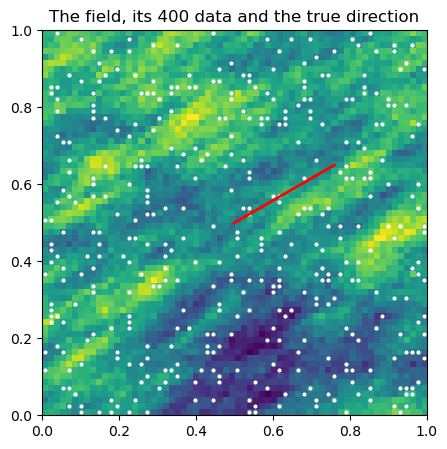

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter, map_coordinates, sobel
from scipy.optimize import curve_fit

import spatialize
from spatialize.gs.esi import esi_griddata, esi_pareto_hparams_search
import spatialize.gs.esi.scorefunction as sf

spatialize.session.set(empty_cells="coarsen", progress=False)

m = 64
grid = (np.arange(m) + 0.5) / m
nodes = np.stack(np.meshgrid(grid, grid), -1).reshape(-1, 2)      # x runs fastest, maps are [y, x]
xi = np.stack(np.meshgrid(grid, grid))

def simulate(angle, major, minor, seed, n_data=400):
    t = np.radians(angle)
    rotation = np.array([[np.cos(t), np.sin(t)], [-np.sin(t), np.cos(t)]])
    scaled = nodes @ rotation.T / np.array([major, minor])
    distance = np.sqrt(((scaled[:, None] - scaled[None]) ** 2).sum(-1))
    rng = np.random.default_rng(seed)
    field = np.linalg.cholesky(np.exp(-distance) + 1e-8 * np.eye(len(nodes))) @ rng.standard_normal(len(nodes))
    picked = rng.choice(len(nodes), n_data, replace=False)
    return field.reshape(m, m), nodes[picked], field[picked]

angle, major, minor = 30.0, 0.25, 0.08
truth, points, values = simulate(angle, major, minor, seed=7)

fig, ax = plt.subplots(figsize=(5.4, 5))
ax.imshow(truth, origin="lower", extent=(0, 1, 0, 1), cmap="viridis")
ax.scatter(points[:, 0], points[:, 1], s=4, c="white")
ax.plot([0.5, 0.5 + 0.3 * np.cos(np.radians(angle))], [0.5, 0.5 + 0.3 * np.sin(np.radians(angle))], "r-", lw=2)
ax.set_title("The field, its 400 data and the true direction")
plt.show()

### Three measurements

We need the same three numbers from every source, the direction of elongation and the scale of the
correlation along it and across it.

- The **direction** of a map comes from its structure tensor, the average of the products of its
  gradients. The gradients point across the structures, so the elongation lies at right angles to the
  dominant gradient. The *coherence*, between 0 and 1, says how strong that direction is.
- The **directional variogram** of a map compares the map with a copy of itself shifted along a
  direction, half the mean squared difference at each lag.
- The **correlation length** along a direction is the lag at which the correlation of the map with its
  shifted copy, one minus the variogram over the variance, first falls below $e^{-1}$. For the
  exponential covariance the field was simulated with, $e^{-h/a}$, that lag is the scale $a$ itself,
  so we read the scale without fitting a model.

In [2]:
def direction(z):
    gx, gy = sobel(z, axis=1), sobel(z, axis=0)
    jxx, jyy, jxy = (gaussian_filter(a, 2.0).mean() for a in (gx * gx, gy * gy, gx * gy))
    mu = np.linalg.eigvalsh([[jxx, jxy], [jxy, jyy]])
    theta = (np.degrees(0.5 * np.arctan2(2 * jxy, jxx - jyy)) + 90.0) % 180.0
    return theta, (mu[1] - mu[0]) / (mu[1] + mu[0])

lags = np.arange(1, 33) / m

def map_variogram(z, theta):
    u = np.array([np.sin(np.radians(theta)), np.cos(np.radians(theta))]) * m      # pixels per unit, (dy, dx)
    yy, xx = np.mgrid[0:m, 0:m].astype(float)
    out = []
    for h in lags:
        y2, x2 = yy + h * u[0], xx + h * u[1]
        inside = (y2 >= 0) & (y2 <= m - 1) & (x2 >= 0) & (x2 <= m - 1)
        shifted = map_coordinates(z, [y2[inside], x2[inside]], order=1)
        out.append(0.5 * np.mean((z[inside] - shifted) ** 2))
    return np.array(out)

def correlation_length(z, theta):
    correlation = 1 - map_variogram(z, theta) / np.var(z)
    below = np.nonzero(correlation < np.exp(-1))[0]
    if len(below) == 0:
        return lags[-1]                     # at least the longest lag
    k = below[0]
    h0, r0 = (0.0, 1.0) if k == 0 else (lags[k - 1], correlation[k - 1])
    return h0 + (r0 - np.exp(-1)) / (r0 - correlation[k]) * (lags[k] - h0)

def exponential(h, sill, scale):
    return sill * (1 - np.exp(-h / scale))

def fit_scale(h, gamma):
    (sill, scale), _ = curve_fit(exponential, h, gamma, p0=[1.0, 0.1], bounds=([0.01, 0.005], [10.0, 2.0]))
    return sill, scale

def summary(theta, along, across):
    return {"direction (°)": theta, "scale along": along, "scale across": across, "ratio": along / across}

theta_truth, _ = direction(truth)
rows = {"model of the simulation": summary(angle, major, minor),
        "the field itself": summary(theta_truth, correlation_length(truth, theta_truth),
                                    correlation_length(truth, theta_truth + 90))}
pd.DataFrame(rows).T.round(3)

,direction (°),scale along,scale across,ratio
model of the simulation,30.000,0.250,0.080,3.125
the field itself,27.199,0.234,0.115,2.024


The realisation differs a little from its model, as any finite sample of a random field does. Its elongation lies at 27°, with scales of about 0.23 and 0.12. These measured values of the field
itself are the targets of what follows, since no method sees more than the realisation.

### The classical route

The experimental variogram of the data, by direction, takes the pairs whose separation points within
11.25° of a direction, bins them by distance and averages half their squared differences in each bin.
We do so every 15°, fit the exponential model in each direction, and take the direction of longest
scale as the major axis, the one at right angles as the minor.

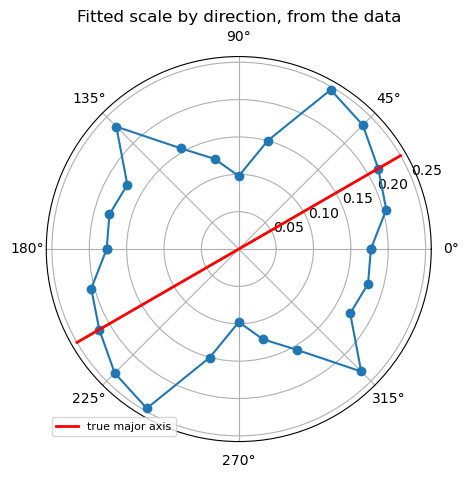

,classical route
direction (°),60.000
scale along,0.246
scale across,0.172
ratio,1.430


In [3]:
def data_variograms(points, values, bins=np.linspace(0, 0.5, 16), tolerance=11.25):
    i, j = np.triu_indices(len(points), 1)
    sep = points[j] - points[i]
    dist = np.hypot(sep[:, 0], sep[:, 1])
    azimuth = np.degrees(np.arctan2(sep[:, 1], sep[:, 0])) % 180
    half_sq = 0.5 * (values[i] - values[j]) ** 2
    result = {}
    for theta in range(0, 180, 15):
        sel = (np.abs((azimuth - theta + 90) % 180 - 90) <= tolerance) & (dist < bins[-1])
        which = np.digitize(dist[sel], bins)
        keep = [b for b in range(1, len(bins)) if (which == b).sum() > 20]
        h = np.array([dist[sel][which == b].mean() for b in keep])
        gamma = np.array([half_sq[sel][which == b].mean() for b in keep])
        result[theta] = (h, gamma, fit_scale(h, gamma)[1])
    return result

experimental = data_variograms(points, values)
theta_classical = max(experimental, key=lambda t: experimental[t][2])
classical = summary(theta_classical, experimental[theta_classical][2], experimental[(theta_classical + 90) % 180][2])

fig, ax = plt.subplots(subplot_kw={"projection": "polar"}, figsize=(5, 5))
directions = np.array(list(experimental) + [180])
scales = np.array([experimental[t][2] for t in experimental] + [experimental[0][2]])
for sign in (0, 180):
    ax.plot(np.radians(directions + sign), scales, "o-", color="C0")
ax.plot(np.radians([angle, angle + 180]), [major, major], "r-", lw=2, label="true major axis")
ax.set_title("Fitted scale by direction, from the data")
ax.legend(loc="lower left", fontsize=8)
plt.show()
pd.Series(classical).round(3).to_frame("classical route")

The fitted scales wander from one direction to the next, the longest falling at 60°, thirty degrees
away from the elongation of the field. Each direction uses a few hundred pairs spread over fifteen bins,
so a handful of pairs can move a fitted scale. With other bins, tolerances or minimum counts the answer
changes again. That freedom is the inductive bias of the manual route.

### The ensemble route

The Pareto search chooses the granularity for the adaptive IDW, the decoder that fits a direction in
each cell. At the knee we estimate the grid, take the direction from the map, then draw the members
with the weighted draw of the same decoder, `wdraw_adaptiveidw`, whose members are data values chosen
with the adaptive weights.

alpha at the knee 0.95, direction of the map 25°, coherence 0.42


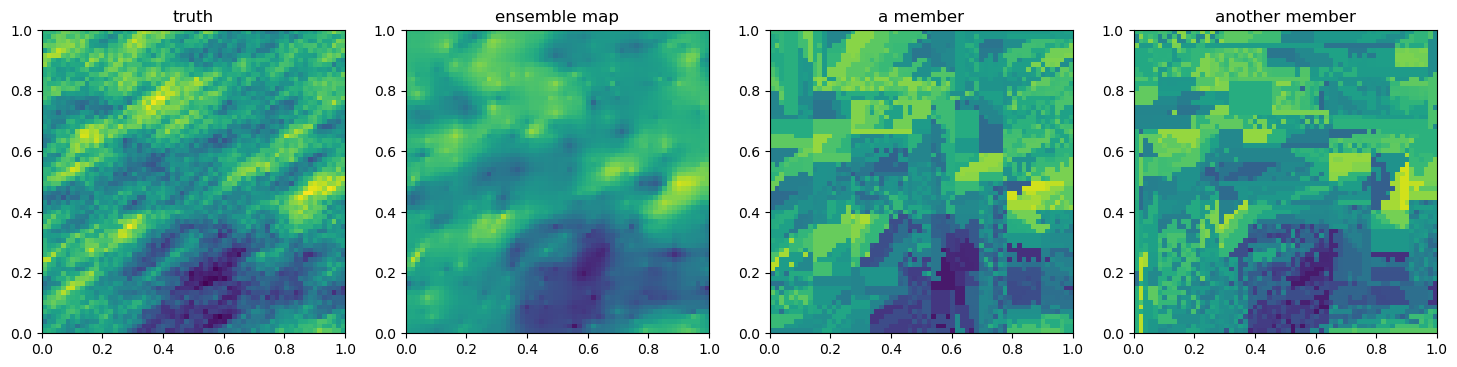

In [4]:
alphas = [0.8, 0.9, 0.95, 0.98]

def ensemble_route(points, values):
    search = esi_pareto_hparams_search(points, values, local_interpolator="adaptiveidw", n_partitions=[100],
                                       alpha=alphas, k="loo", scoring=sf.mae, seed=0)
    knee = search.best_result(strategy="knee")["alpha"]
    estimate = esi_griddata(points, values, xi, local_interpolator="adaptiveidw", n_partitions=100,
                            alpha=knee, seed=0).estimation()
    theta, coherence = direction(estimate)
    members = esi_griddata(points, values, xi, local_interpolator="wdraw_adaptiveidw", n_partitions=100,
                           alpha=knee, seed=0).esi_samples()
    gamma = {side: np.mean([map_variogram(members[..., k], theta + side) for k in range(members.shape[-1])], axis=0)
             for side in (0, 90)}
    length = {side: np.mean([correlation_length(members[..., k], theta + side) for k in range(members.shape[-1])])
              for side in (0, 90)}
    return dict(knee=knee, estimate=estimate, theta=theta, coherence=coherence, members=members, gamma=gamma,
                length=length)

route = ensemble_route(points, values)
print(f"alpha at the knee {route['knee']}, direction of the map {route['theta']:.0f}°, "
      f"coherence {route['coherence']:.2f}")

fig, axes = plt.subplots(1, 4, figsize=(18, 4.6))
for ax, (title, z) in zip(axes, [("truth", truth), ("ensemble map", route["estimate"]),
                                 ("a member", route["members"][..., 0]), ("another member", route["members"][..., 1])]):
    ax.imshow(z, origin="lower", extent=(0, 1, 0, 1), cmap="viridis", vmin=truth.min(), vmax=truth.max())
    ax.set_title(title)
plt.show()

The map follows the elongated patches of the field, smoother than it. Each member is blockier, made of
data values placed in the cells of one partition, while the broad pattern of the field stays in each, the
dark patch near the bottom above all. The direction of the map lies within two degrees of the field's.

### The variogram along and across

We now compare the variograms along the direction found and across it, from the field itself, from
the data, from the map and from the members.

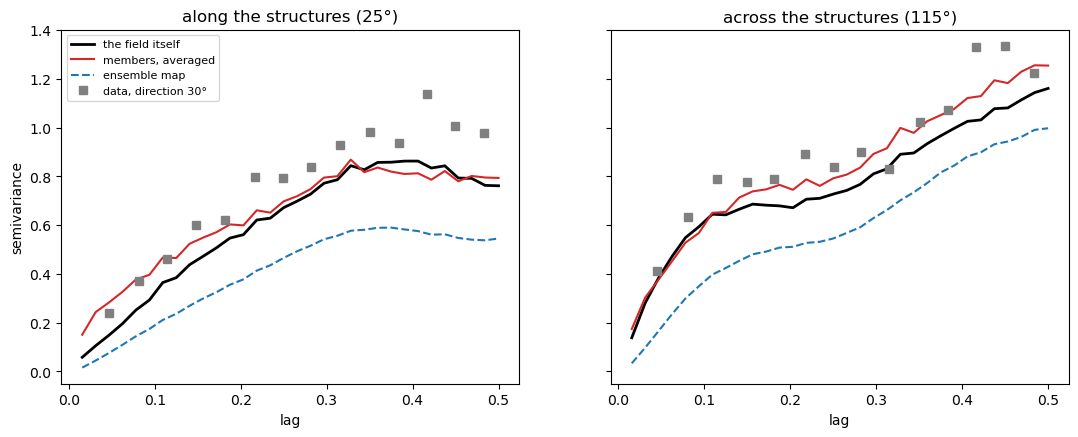

,direction (°),scale along,scale across,ratio
the field itself,27.199,0.234,0.115,2.024
classical route,60.000,0.246,0.172,1.430
ensemble map,25.410,0.264,0.169,1.560
ensemble members,25.410,0.237,0.126,1.876


In [5]:
theta = route["theta"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for ax, side, label in zip(axes, (0, 90), ("along", "across")):
    ax.plot(lags, map_variogram(truth, theta + side), "k-", lw=2, label="the field itself")
    ax.plot(lags, route["gamma"][side], "C3-", label="members, averaged")
    ax.plot(lags, map_variogram(route["estimate"], theta + side), "C0--", label="ensemble map")
    nearest = min(experimental, key=lambda t: abs((t - theta - side + 90) % 180 - 90))
    h, gamma, _ = experimental[nearest]
    ax.plot(h, gamma, "s", color="0.5", label=f"data, direction {nearest}°")
    ax.set_title(f"{label} the structures ({(theta + side) % 180:.0f}°)")
    ax.set_xlabel("lag")
axes[0].set_ylabel("semivariance")
axes[0].legend(fontsize=8)
plt.show()

ensemble = summary(theta, route["length"][0], route["length"][90])
map_only = summary(theta, correlation_length(route["estimate"], theta), correlation_length(route["estimate"], theta + 90))
pd.DataFrame({"the field itself": rows["the field itself"], "classical route": classical,
              "ensemble map": map_only, "ensemble members": ensemble}).T.round(3)

The variogram of the members follows that of the field in both directions. Only at the shortest lags
along the structures does it start higher, since the draw picks a datum anew at each location. The
map's variogram rises more slowly and stays below the field's, so its correlation lengths come out
longer, across the structures above all. The data's points scatter above and below the field's curve,
the scatter that misleads the fit by direction.

### On other fields

One field could flatter a method. We repeat both routes on five more fields, with other directions and
ratios, one of them isotropic. For the isotropic field the direction means nothing, which the coherence
of the map should show.

In [6]:
cases = [(30, 0.25, 0.08, 7), (75, 0.30, 0.10, 11), (120, 0.20, 0.10, 13), (160, 0.35, 0.07, 17),
         (10, 0.15, 0.05, 19), (0, 0.15, 0.15, 23)]
table = []
for case_angle, case_major, case_minor, seed in cases:
    f, pts, vals = simulate(case_angle, case_major, case_minor, seed)
    th_field, _ = direction(f)
    field_scales = [correlation_length(f, th_field + s) for s in (0, 90)]
    exp_case = data_variograms(pts, vals)
    th_classical = max(exp_case, key=lambda t: exp_case[t][2])
    r = ensemble_route(pts, vals)
    table.append({"field": f"{case_angle}°, {case_major}/{case_minor}" if case_major != case_minor else f"isotropic, {case_major}",
                  "field dir": th_field, "classical dir": th_classical, "ensemble dir": r["theta"],
                  "coherence": r["coherence"],
                  "field along": field_scales[0], "field across": field_scales[1],
                  "classical along": exp_case[th_classical][2],
                  "classical across": exp_case[(th_classical + 90) % 180][2],
                  "ensemble along": r["length"][0], "ensemble across": r["length"][90]})
pd.DataFrame(table).set_index("field").round(2)

,field dir,classical dir,ensemble dir,coherence,field along,field across,classical along,classical across,ensemble along,ensemble across
field,,,,,,,,,,
"30°, 0.25/0.08",27.20,60,25.41,0.42,0.23,0.12,0.25,0.17,0.24,0.13
"75°, 0.3/0.1",78.57,90,81.78,0.45,0.26,0.16,0.68,0.31,0.27,0.16
"120°, 0.2/0.1",116.58,105,120.66,0.21,0.14,0.09,0.14,0.03,0.13,0.09
"160°, 0.35/0.07",161.41,150,159.27,0.60,0.36,0.09,2.00,0.08,0.35,0.09
"10°, 0.15/0.05",6.88,15,3.79,0.48,0.12,0.04,0.16,0.04,0.13,0.05
"isotropic, 0.15",107.87,90,78.43,0.02,0.12,0.14,0.21,0.11,0.13,0.12


On every anisotropic field the direction of the map lies within about 4° of the field's, while the
classical route misses by 8° to 33°. The correlation lengths of the members stay within 0.02 of the
field's. The classical route reaches 0.68 and 2.00, the bound of its fit, where the field's lengths are
0.26 and 0.36. On the isotropic field the coherence of the map, 0.02, says there is no direction to
report, and the two lengths of the members agree, while the classical route reports one length almost
twice the other.

### From the measurements to a variogram

The ensemble route gives a direction and a correlation length along it and across it. With the variance
of the data as the sill, they make an exponential variogram with geometric anisotropy, the form kriging
software takes, its practical range three times each length. Spatialize's kriging decoder is isotropic,
so it takes a single range. The tutorial on that decoder chooses its parameters with the Pareto search
instead, scoring each candidate by its predictions, which the range barely moves. Here the variogram is
an estimate of the field's structure, to be read and reported, not only a setting of a predictor.

## What can go wrong

- **A direction on an isotropic field.** The structure tensor always returns an angle. Read the
  coherence first. Near zero, the field has no preferred direction, so the angle is noise.
- **Ranges from the map.** An averaged map is smoother than the field, so its variogram rises too slowly, stretching its correlation lengths. Use the members of a drawing decoder for the ranges.
- **Ranges near the size of the domain.** A lag of a quarter of the domain already compares few pairs
  of locations, so long scales are poorly determined by any route. Report them as at least that long.
- **A model fitted to the members.** Their variogram starts with a jump, since the draw picks a datum
  anew at each location. A model without a nugget reads the jump as a shorter scale, while one with a
  nugget leaves the scale poorly determined. The correlation length avoids both.
- **A field whose structure changes from place to place.** A single direction and pair of scales
  summarise the whole domain. Measure them on parts of the map to see whether they hold everywhere.

## Try it yourself

1. Halve the number of data and compare how far each route moves.
2. Simulate with a spherical covariance and fit the exponential model anyway. Which route notices?
3. Use the uniform draw (`local_interpolator="draw"`) for the members and compare the ranges.
4. Give the inferred anisotropy to PyKrige's ordinary kriging (`anisotropy_angle`, `anisotropy_scaling`)
   and compare its map with the adaptive IDW's.

## Next

- *The kriging decoder and global kriging*, where the variogram is chosen by the Pareto search.
- *The probabilistic decoders*, for the drawing decoders whose members we used.
- *Choosing an ensemble with the Pareto search*, for the knee.
- The documentation's [Decoders](https://spatialize.readthedocs.io/en/latest/theory/decoders.html) (theory).